
# Notebook 09 — Predictor Interpretation and Feature Stability

**Project:** WR-MovementIQ  
**Research:** Beyond the 40-Yard Dash

## Objectives

1. Examine traditional Combine predictor relationships.
2. Examine tracking-derived Combine predictor relationships.
3. Investigate multicollinearity.
4. Estimate fold-specific standardized Ridge coefficients.
5. Evaluate coefficient sign stability.
6. Investigate associations with NFL P95 and peak speed.
7. Identify predictors requiring further robustness analysis.

## Research safeguards

- Preserve the frozen core analysis dataset.
- Preserve Notebook 07 outer folds.
- Use selected alpha values from Notebook 08.
- Fit scaling using training data only.
- Do not interpret coefficients as causal effects.
- Do not modify existing OOF predictions.


In [1]:

from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

warnings.filterwarnings("ignore")

# Resolve project root
HERE = Path.cwd().resolve()

if (HERE / "data").exists() and (HERE / "reports").exists():
    ROOT = HERE
elif (HERE.parent / "data").exists() and (HERE.parent / "reports").exists():
    ROOT = HERE.parent
else:
    raise FileNotFoundError(
        f"Cannot locate project root from {HERE}"
    )

DATASET_PATH = (
    ROOT / "data/features/wr_analysis_dataset_core_common.parquet"
)

FOLD_PATH = (
    ROOT / "reports/modeling_design/outer_grouped_fold_assignments.csv"
)

OOF_PATH = (
    ROOT / "reports/nested_ridge_modeling/oof_predictions.csv"
)

TUNING_PATH = (
    ROOT / "reports/nested_ridge_modeling/inner_tuning_results.csv"
)

OUT_DIR = ROOT / "reports/predictor_interpretation"
OUT_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", ROOT)
print("Dataset:", DATASET_PATH)
print("Output:", OUT_DIR)


Project root: D:\PROJECTS\WR-MovementIQ
Dataset: D:\PROJECTS\WR-MovementIQ\data\features\wr_analysis_dataset_core_common.parquet
Output: D:\PROJECTS\WR-MovementIQ\reports\predictor_interpretation


In [2]:

for path in [DATASET_PATH, FOLD_PATH, OOF_PATH, TUNING_PATH]:
    if not path.exists():
        raise FileNotFoundError(path)

data = pd.read_parquet(DATASET_PATH)
folds_raw = pd.read_csv(FOLD_PATH)
oof = pd.read_csv(OOF_PATH)
tuning = pd.read_csv(TUNING_PATH)

data["nfl_id"] = pd.to_numeric(
    data["nfl_id"], errors="raise"
).astype("int64")

folds_raw["nfl_id"] = pd.to_numeric(
    folds_raw["nfl_id"], errors="raise"
).astype("int64")

folds_raw["outer_fold"] = pd.to_numeric(
    folds_raw["outer_fold"], errors="raise"
).astype(int)

folds = (
    folds_raw[["nfl_id", "outer_fold"]]
    .drop_duplicates()
    .copy()
)

assert folds.groupby("nfl_id")["outer_fold"].nunique().eq(1).all()
assert folds["nfl_id"].is_unique

assert len(data) == 93
assert data["nfl_id"].nunique() == 54
assert folds["nfl_id"].nunique() == 54
assert folds["outer_fold"].nunique() == 5

print("Dataset rows:", len(data))
print("Receivers:", data.nfl_id.nunique())
print("Outer folds:", sorted(folds.outer_fold.unique()))
print("OOF rows:", len(oof))
print("Tuning rows:", len(tuning))

display(folds.groupby("outer_fold").nfl_id.nunique())


Dataset rows:

 93
Receivers: 54
Outer folds: [1, 2, 3, 4, 5]
OOF rows: 2232
Tuning rows: 90


outer_fold
1    11
2    11
3    11
4    10
5    11
Name: nfl_id, dtype: int64

In [3]:

TRADITIONAL = [
    "forty",
    "vertical",
    "broad_jump"
]

TRACKING = [
    "combine_mean_speed_median_across_drills",
    "combine_peak_speed_median_across_drills",
    "combine_p95_speed_median_across_drills",
    "combine_mean_acceleration_median_across_drills",
    "combine_peak_acceleration_median_across_drills",
    "combine_path_efficiency_median_across_drills"
]

FEATURE_SETS = {
    "TRADITIONAL": TRADITIONAL,
    "TRACKING": TRACKING,
    "COMBINED": TRADITIONAL + TRACKING
}

OUTCOMES = [
    "game_mean_speed_raw_median",
    "game_p95_speed_raw_median",
    "game_peak_speed_raw_median",
    "game_mean_acceleration_raw_median",
    "game_peak_acceleration_raw_median",
    "game_path_efficiency_median"
]

PRIMARY_SPEED = [
    "game_p95_speed_raw_median",
    "game_peak_speed_raw_median"
]

required = (
    TRADITIONAL + TRACKING + OUTCOMES
)

missing = [
    c for c in required
    if c not in data.columns
]

assert not missing, f"Missing columns: {missing}"

print("Traditional predictors:", len(TRADITIONAL))
print("Tracking predictors:", len(TRACKING))
print("Combined predictors:", len(TRADITIONAL + TRACKING))


Traditional predictors: 3
Tracking predictors: 6
Combined predictors: 9


In [4]:

rows = []

for feature in TRADITIONAL + TRACKING:

    x = pd.to_numeric(data[feature], errors="coerce")

    rows.append({
        "predictor": feature,
        "group": (
            "TRADITIONAL"
            if feature in TRADITIONAL
            else "TRACKING"
        ),
        "observations": x.notna().sum(),
        "missing_pct": x.isna().mean() * 100,
        "mean": x.mean(),
        "std": x.std(),
        "median": x.median(),
        "minimum": x.min(),
        "maximum": x.max()
    })

predictor_summary = pd.DataFrame(rows)

predictor_summary.to_csv(
    OUT_DIR / "predictor_distribution_summary.csv",
    index=False
)

display(predictor_summary)


,predictor,group,observations,missing_pct,mean,std,median,minimum,maximum
0,forty,TRADITIONAL,93,0.0,4.465269,0.080886,4.450000,4.300000,4.690000
1,vertical,TRADITIONAL,93,0.0,37.747312,2.660729,38.000000,29.000000,42.500000
2,broad_jump,TRADITIONAL,93,0.0,126.440860,4.633203,127.000000,116.000000,136.000000
3,combine_mean_speed_median_across_drills,TRACKING,93,0.0,5.686593,0.314339,5.681765,4.898461,6.406196
4,combine_peak_speed_median_across_drills,TRACKING,93,0.0,8.294605,0.223605,8.303333,7.840000,8.698245
5,combine_p95_speed_median_across_drills,TRACKING,93,0.0,8.186691,0.200977,8.199333,7.761000,8.548327
6,combine_mean_acceleration_median_across_drills,TRACKING,93,0.0,3.285356,0.284502,3.297996,2.604155,3.807039
7,combine_peak_acceleration_median_across_drills,TRACKING,93,0.0,6.685642,0.506903,6.662594,5.200097,7.532192
8,combine_path_efficiency_median_across_drills,TRACKING,93,0.0,0.896598,0.018697,0.898749,0.833971,0.953161


,predictor_a,predictor_b,spearman_rho,absolute_correlation
26,combine_peak_speed_median_across_drills,combine_p95_speed_median_across_drills,0.970145,0.970145
8,vertical,broad_jump,0.644162,0.644162
35,combine_peak_acceleration_median_across_drills,combine_path_efficiency_median_across_drills,-0.523581,0.523581
33,combine_mean_acceleration_median_across_drills,combine_peak_acceleration_median_across_drills,0.467888,0.467888
34,combine_mean_acceleration_median_across_drills,combine_path_efficiency_median_across_drills,-0.405104,0.405104
28,combine_peak_speed_median_across_drills,combine_peak_acceleration_median_across_drills,0.327163,0.327163
4,forty,combine_p95_speed_median_across_drills,-0.325811,0.325811
31,combine_p95_speed_median_across_drills,combine_peak_acceleration_median_across_drills,0.323004,0.323004
0,forty,vertical,-0.319364,0.319364
3,forty,combine_peak_speed_median_across_drills,-0.298468,0.298468


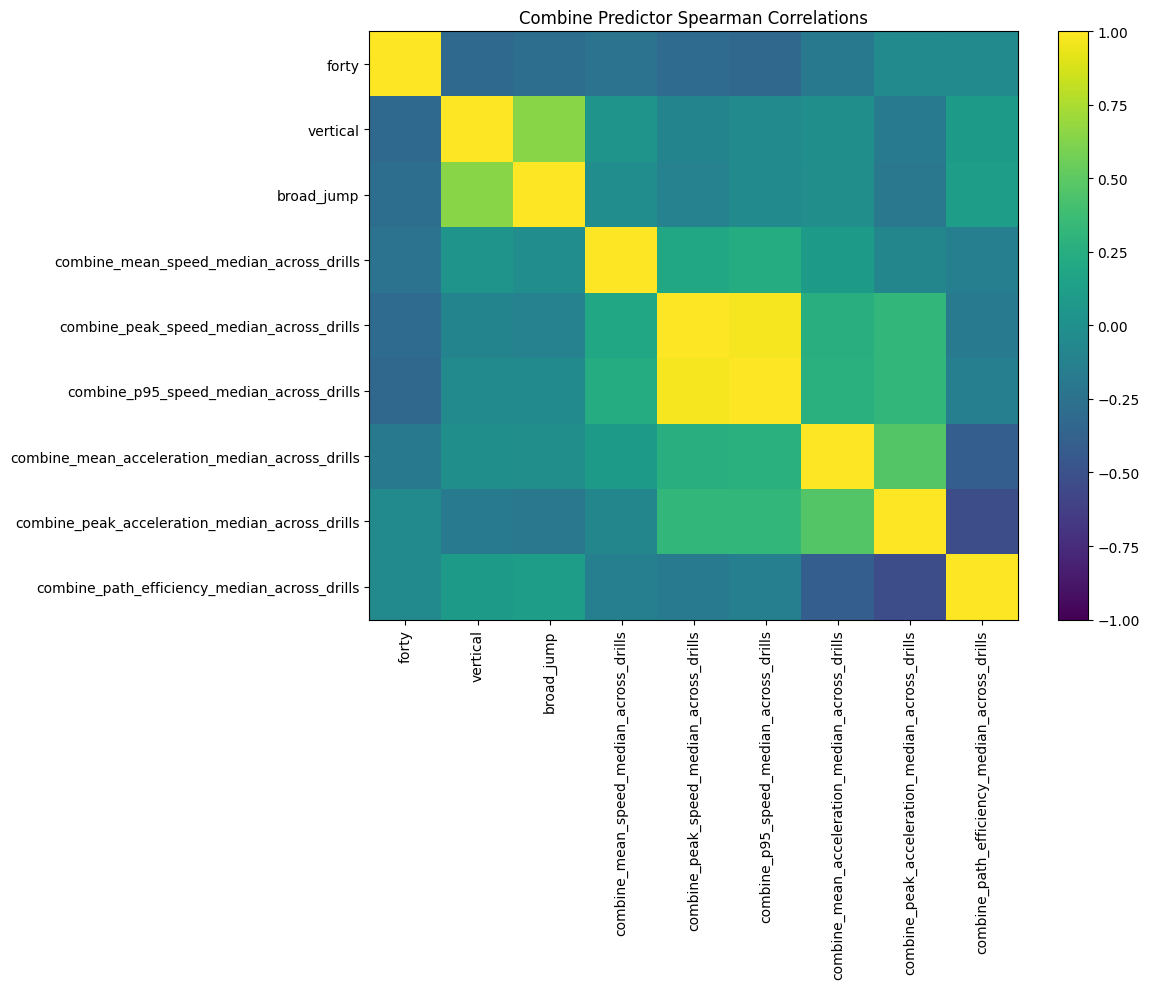

In [5]:

predictors = TRADITIONAL + TRACKING

correlation = data[predictors].corr(
    method="spearman"
)

correlation.to_csv(
    OUT_DIR / "predictor_spearman_correlation_matrix.csv"
)

pairs = []

for i, first in enumerate(predictors):

    for second in predictors[i + 1:]:

        rho = correlation.loc[first, second]

        pairs.append({
            "predictor_a": first,
            "predictor_b": second,
            "spearman_rho": rho,
            "absolute_correlation": abs(rho)
        })

correlation_pairs = (
    pd.DataFrame(pairs)
    .sort_values("absolute_correlation", ascending=False)
)

correlation_pairs.to_csv(
    OUT_DIR / "predictor_correlation_pairs.csv",
    index=False
)

display(correlation_pairs)

fig, ax = plt.subplots(figsize=(12, 10))

image = ax.imshow(
    correlation.values,
    vmin=-1,
    vmax=1,
    aspect="auto"
)

ax.set_xticks(range(len(predictors)))
ax.set_yticks(range(len(predictors)))

ax.set_xticklabels(predictors, rotation=90)
ax.set_yticklabels(predictors)

fig.colorbar(image, ax=ax)

ax.set_title("Combine Predictor Spearman Correlations")

fig.tight_layout()

fig.savefig(
    OUT_DIR / "predictor_correlation_heatmap.png",
    dpi=180
)

plt.show()


In [6]:

association_rows = []

for outcome in OUTCOMES:

    for predictor in predictors:

        pair = data[
            [outcome, predictor]
        ].apply(
            pd.to_numeric,
            errors="coerce"
        ).dropna()

        rho = (
            pair[outcome].corr(
                pair[predictor],
                method="spearman"
            )
            if len(pair) >= 5
            else np.nan
        )

        association_rows.append({
            "outcome": outcome,
            "predictor": predictor,
            "group": (
                "TRADITIONAL"
                if predictor in TRADITIONAL
                else "TRACKING"
            ),
            "n": len(pair),
            "spearman_rho": rho
        })

associations = pd.DataFrame(association_rows)

associations.to_csv(
    OUT_DIR / "univariate_spearman_associations.csv",
    index=False
)

display(
    associations[
        associations.outcome.isin(PRIMARY_SPEED)
    ].sort_values(
        ["outcome", "spearman_rho"],
        ascending=[True, False]
    )
)


,outcome,predictor,group,n,spearman_rho
13,game_p95_speed_raw_median,combine_peak_speed_median_across_drills,TRACKING,93,0.292682
14,game_p95_speed_raw_median,combine_p95_speed_median_across_drills,TRACKING,93,0.265094
15,game_p95_speed_raw_median,combine_mean_acceleration_median_across_drills,TRACKING,93,0.084805
16,game_p95_speed_raw_median,combine_peak_acceleration_median_across_drills,TRACKING,93,0.015991
12,game_p95_speed_raw_median,combine_mean_speed_median_across_drills,TRACKING,93,-0.007507
11,game_p95_speed_raw_median,broad_jump,TRADITIONAL,93,-0.059927
10,game_p95_speed_raw_median,vertical,TRADITIONAL,93,-0.157846
17,game_p95_speed_raw_median,combine_path_efficiency_median_across_drills,TRACKING,93,-0.208017
9,game_p95_speed_raw_median,forty,TRADITIONAL,93,-0.354738
22,game_peak_speed_raw_median,combine_peak_speed_median_across_drills,TRACKING,93,0.290367


In [7]:

print("TUNING FILE COLUMNS")
print(tuning.columns.tolist())

display(tuning.head(15))

# Identify columns without assuming a fixed schema
lower_cols = {
    c.lower(): c
    for c in tuning.columns
}

def find_column(candidates):

    for candidate in candidates:

        if candidate in lower_cols:
            return lower_cols[candidate]

    return None

OUTCOME_COL = find_column([
    "outcome",
    "target"
])

MODEL_COL = find_column([
    "model",
    "specification",
    "model_name"
])

FOLD_COL = find_column([
    "outer_fold",
    "fold"
])

ALPHA_COL = find_column([
    "best_alpha",
    "selected_alpha",
    "alpha"
])

SCORE_COL = find_column([
    "inner_best_mae",
    "mean_validation_mae",
    "validation_mae",
    "mean_mae"
])

print({
    "outcome": OUTCOME_COL,
    "model": MODEL_COL,
    "fold": FOLD_COL,
    "alpha": ALPHA_COL,
    "score": SCORE_COL
})

if not all([
    OUTCOME_COL,
    MODEL_COL,
    FOLD_COL,
    ALPHA_COL
]):
    raise ValueError(
        "Cannot identify the selected-alpha schema. "
        "Inspect the tuning columns printed above before continuing."
    )


TUNING FILE COLUMNS
['outcome', 'model', 'outer_fold', 'best_alpha', 'inner_best_mae', 'train_rows', 'test_rows', 'train_players', 'test_players', 'alpha_at_grid_boundary']


,outcome,model,outer_fold,best_alpha,inner_best_mae,train_rows,test_rows,train_players,test_players,alpha_at_grid_boundary
0,game_mean_speed_raw_median,TRADITIONAL,1,100.0,0.393284,74,19,43,11,False
1,game_mean_speed_raw_median,TRADITIONAL,2,100.0,0.396993,74,19,43,11,False
2,game_mean_speed_raw_median,TRADITIONAL,3,100.0,0.388015,74,19,43,11,False
3,game_mean_speed_raw_median,TRADITIONAL,4,100000.0,0.321494,75,18,44,10,True
4,game_mean_speed_raw_median,TRADITIONAL,5,1000.0,0.390056,75,18,43,11,False
5,game_mean_speed_raw_median,TRACKING,1,100.0,0.392403,74,19,43,11,False
6,game_mean_speed_raw_median,TRACKING,2,100000.0,0.412086,74,19,43,11,True
7,game_mean_speed_raw_median,TRACKING,3,10.0,0.372537,74,19,43,11,False
8,game_mean_speed_raw_median,TRACKING,4,100000.0,0.321489,75,18,44,10,True
9,game_mean_speed_raw_median,TRACKING,5,100000.0,0.391161,75,18,43,11,True


{'outcome': 'outcome', 'model': 'model', 'fold': 'outer_fold', 'alpha': 'best_alpha', 'score': 'inner_best_mae'}


In [8]:

t = tuning.copy()

t[FOLD_COL] = pd.to_numeric(
    t[FOLD_COL], errors="coerce"
)

t[ALPHA_COL] = pd.to_numeric(
    t[ALPHA_COL], errors="coerce"
)

t = t.dropna(
    subset=[
        OUTCOME_COL,
        MODEL_COL,
        FOLD_COL,
        ALPHA_COL
    ]
)

t[FOLD_COL] = t[FOLD_COL].astype(int)

KEYS = [
    OUTCOME_COL,
    MODEL_COL,
    FOLD_COL
]

if SCORE_COL:

    t[SCORE_COL] = pd.to_numeric(
        t[SCORE_COL],
        errors="coerce"
    )

    selected = (
        t.sort_values(SCORE_COL)
        .drop_duplicates(KEYS, keep="first")
    )

else:

    selected = t.drop_duplicates(
        KEYS,
        keep="last"
    )

alpha_lookup = {}

for _, row in selected.iterrows():

    key = (
        str(row[OUTCOME_COL]),
        str(row[MODEL_COL]).upper(),
        int(row[FOLD_COL])
    )

    alpha_lookup[key] = float(
        row[ALPHA_COL]
    )

print("Selected alpha combinations:", len(alpha_lookup))

print("Model labels:")
print(sorted(set(k[1] for k in alpha_lookup)))

print("Outcome labels:")
print(sorted(set(k[0] for k in alpha_lookup)))


Selected alpha combinations: 90
Model labels:
['COMBINED', 'TRACKING', 'TRADITIONAL']
Outcome labels:
['game_mean_acceleration_raw_median', 'game_mean_speed_raw_median', 'game_p95_speed_raw_median', 'game_path_efficiency_median', 'game_peak_acceleration_raw_median', 'game_peak_speed_raw_median']


In [9]:

coefficient_rows = []

for outcome in OUTCOMES:

    for model_name, features in FEATURE_SETS.items():

        for fold_id in sorted(folds.outer_fold.unique()):

            key = (
                outcome,
                model_name,
                int(fold_id)
            )

            if key not in alpha_lookup:
                continue

            alpha = alpha_lookup[key]

            train_receivers = set(
                folds.loc[
                    folds.outer_fold != fold_id,
                    "nfl_id"
                ]
            )

            train = data[
                data.nfl_id.isin(train_receivers)
            ].copy()

            X = train[features].apply(
                pd.to_numeric,
                errors="coerce"
            )

            y = pd.to_numeric(
                train[outcome],
                errors="coerce"
            )

            valid = (
                y.notna()
                & X.notna().all(axis=1)
            )

            X = X.loc[valid]
            y = y.loc[valid]

            if len(X) < 10:
                continue

            pipeline = Pipeline([
                ("scaler", StandardScaler()),
                ("ridge", Ridge(alpha=alpha))
            ])

            pipeline.fit(X, y)

            model = pipeline.named_steps["ridge"]

            for feature, coefficient in zip(
                features,
                model.coef_
            ):

                coefficient_rows.append({
                    "outcome": outcome,
                    "model": model_name,
                    "outer_fold": int(fold_id),
                    "predictor": feature,
                    "standardized_coefficient": float(coefficient),
                    "selected_alpha": alpha,
                    "training_rows": len(X),
                    "training_receivers": train.loc[
                        X.index,
                        "nfl_id"
                    ].nunique()
                })

coefficients = pd.DataFrame(coefficient_rows)

if coefficients.empty:
    raise RuntimeError(
        "No coefficients generated. Check tuning model labels "
        "and selected alpha records."
    )

coefficients.to_csv(
    OUT_DIR / "fold_specific_standardized_coefficients.csv",
    index=False
)

display(coefficients.head(20))

print("Coefficient records:", len(coefficients))


,outcome,model,outer_fold,predictor,standardized_coefficient,selected_alpha,training_rows,training_receivers
0,game_mean_speed_raw_median,TRADITIONAL,1,forty,-0.066764,100.0,74,43
1,game_mean_speed_raw_median,TRADITIONAL,1,vertical,-0.036003,100.0,74,43
2,game_mean_speed_raw_median,TRADITIONAL,1,broad_jump,-0.011399,100.0,74,43
3,game_mean_speed_raw_median,TRADITIONAL,2,forty,-0.071817,100.0,74,43
4,game_mean_speed_raw_median,TRADITIONAL,2,vertical,-0.051270,100.0,74,43
5,game_mean_speed_raw_median,TRADITIONAL,2,broad_jump,-0.024900,100.0,74,43
6,game_mean_speed_raw_median,TRADITIONAL,3,forty,-0.063467,100.0,74,43
7,game_mean_speed_raw_median,TRADITIONAL,3,vertical,-0.040554,100.0,74,43
8,game_mean_speed_raw_median,TRADITIONAL,3,broad_jump,-0.002109,100.0,74,43
9,game_mean_speed_raw_median,TRADITIONAL,4,forty,-0.000032,100000.0,75,44


Coefficient records: 540


In [10]:

stability = (
    coefficients
    .groupby([
        "outcome",
        "model",
        "predictor"
    ])
    .agg(
        folds=("outer_fold", "nunique"),
        mean_coefficient=(
            "standardized_coefficient",
            "mean"
        ),
        median_coefficient=(
            "standardized_coefficient",
            "median"
        ),
        coefficient_sd=(
            "standardized_coefficient",
            "std"
        ),
        minimum=(
            "standardized_coefficient",
            "min"
        ),
        maximum=(
            "standardized_coefficient",
            "max"
        ),
        positive_folds=(
            "standardized_coefficient",
            lambda x: int((x > 0).sum())
        ),
        negative_folds=(
            "standardized_coefficient",
            lambda x: int((x < 0).sum())
        )
    )
    .reset_index()
)

stability["sign_consistency"] = (
    stability[
        ["positive_folds", "negative_folds"]
    ].max(axis=1)
    / stability["folds"]
)

stability.to_csv(
    OUT_DIR / "coefficient_stability_summary.csv",
    index=False
)

display(
    stability[
        stability.outcome.isin(PRIMARY_SPEED)
    ].sort_values(
        [
            "outcome",
            "model",
            "sign_consistency"
        ],
        ascending=[True, True, False]
    )
)


,outcome,model,predictor,folds,mean_coefficient,median_coefficient,coefficient_sd,minimum,maximum,positive_folds,negative_folds,sign_consistency
37,game_p95_speed_raw_median,COMBINED,combine_mean_acceleration_median_across_drills,5,-0.053945,-0.042757,0.038750,-0.109946,-0.019749,0,5,1.0
38,game_p95_speed_raw_median,COMBINED,combine_mean_speed_median_across_drills,5,-0.062576,-0.059516,0.035357,-0.109481,-0.011243,0,5,1.0
39,game_p95_speed_raw_median,COMBINED,combine_p95_speed_median_across_drills,5,0.033882,0.027427,0.021786,0.007501,0.057531,5,0,1.0
40,game_p95_speed_raw_median,COMBINED,combine_path_efficiency_median_across_drills,5,-0.119096,-0.137486,0.047975,-0.152307,-0.036562,0,5,1.0
42,game_p95_speed_raw_median,COMBINED,combine_peak_speed_median_across_drills,5,0.050547,0.042911,0.035178,0.020443,0.106149,5,0,1.0
43,game_p95_speed_raw_median,COMBINED,forty,5,-0.218055,-0.267696,0.074563,-0.276859,-0.117199,0,5,1.0
44,game_p95_speed_raw_median,COMBINED,vertical,5,-0.129666,-0.179333,0.079697,-0.199305,-0.022609,0,5,1.0
36,game_p95_speed_raw_median,COMBINED,broad_jump,5,-0.014786,-0.007268,0.041986,-0.080608,0.035045,1,4,0.8
41,game_p95_speed_raw_median,COMBINED,combine_peak_acceleration_median_across_drills,5,-0.053927,-0.059275,0.036341,-0.088825,0.000602,1,4,0.8
48,game_p95_speed_raw_median,TRACKING,combine_path_efficiency_median_across_drills,5,-0.033860,-0.006219,0.055998,-0.132706,-0.000053,0,5,1.0


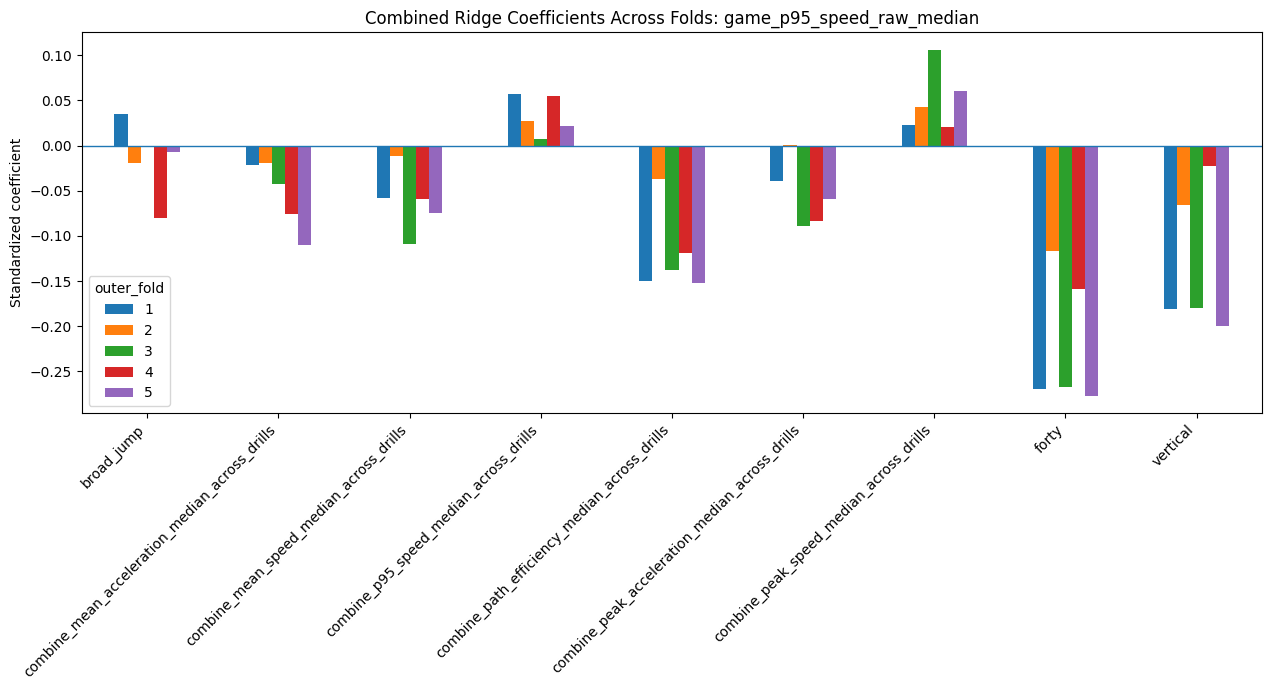

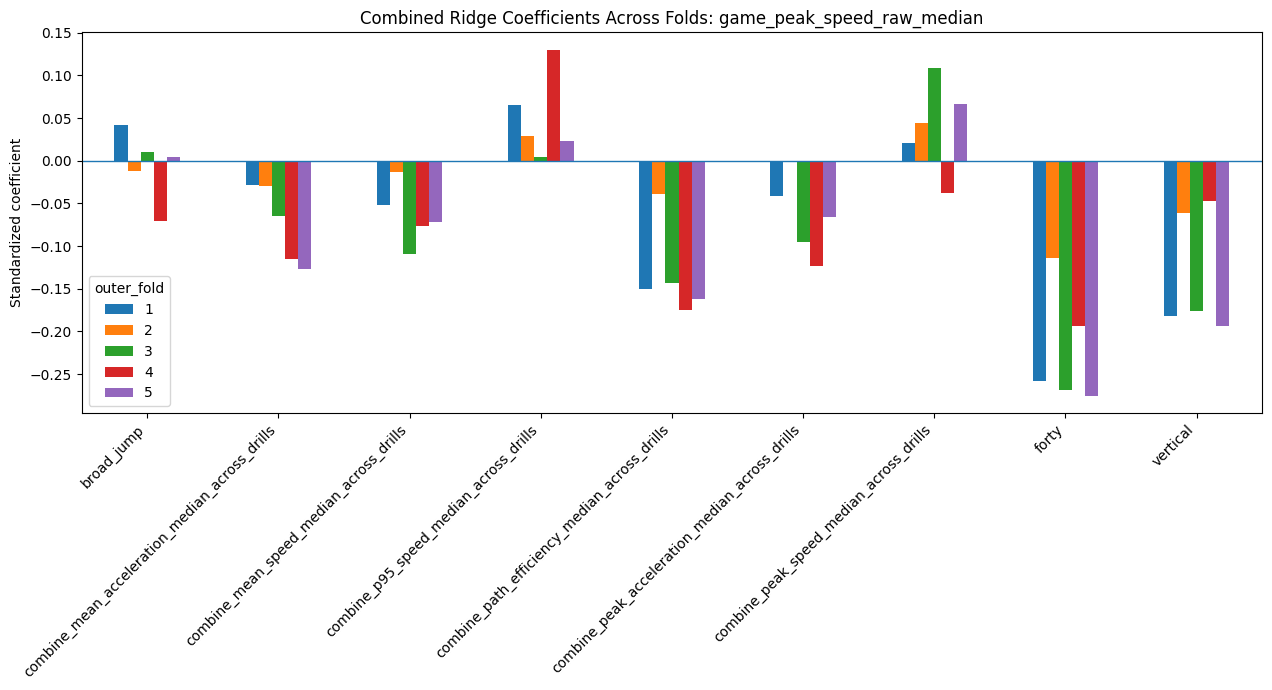

In [11]:

for outcome in PRIMARY_SPEED:

    subset = coefficients[
        (coefficients.outcome == outcome)
        & (coefficients.model == "COMBINED")
    ]

    if subset.empty:
        print("No combined coefficients:", outcome)
        continue

    pivot = subset.pivot(
        index="predictor",
        columns="outer_fold",
        values="standardized_coefficient"
    )

    ax = pivot.plot(
        kind="bar",
        figsize=(13, 7)
    )

    ax.axhline(0, linewidth=1)

    ax.set_title(
        f"Combined Ridge Coefficients Across Folds: {outcome}"
    )

    ax.set_ylabel("Standardized coefficient")
    ax.set_xlabel("")

    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()

    plt.savefig(
        OUT_DIR / f"{outcome}_coefficient_stability.png",
        dpi=180
    )

    plt.show()


In [12]:

oof["actual"] = pd.to_numeric(
    oof["actual"],
    errors="coerce"
)

oof["predicted"] = pd.to_numeric(
    oof["predicted"],
    errors="coerce"
)

oof = oof.dropna(
    subset=["actual", "predicted"]
)

oof_rows = []

for (outcome, model), group in oof.groupby(
    ["outcome", "model"]
):

    actual = group["actual"].to_numpy()
    predicted = group["predicted"].to_numpy()

    oof_rows.append({
        "outcome": outcome,
        "model": model,
        "predictions": len(group),
        "receivers": group.nfl_id.nunique(),
        "mae": np.mean(np.abs(actual - predicted)),
        "rmse": np.sqrt(
            np.mean((actual - predicted) ** 2)
        ),
        "pearson": (
            np.corrcoef(actual, predicted)[0, 1]
            if np.std(actual) > 0 and np.std(predicted) > 0
            else np.nan
        )
    })

oof_summary = pd.DataFrame(oof_rows)

oof_summary.to_csv(
    OUT_DIR / "existing_oof_performance_snapshot.csv",
    index=False
)

display(oof_summary)


,outcome,model,predictions,receivers,mae,rmse,pearson
0,game_mean_acceleration_raw_median,BASELINE,93,54,0.144469,0.183763,-0.233517
1,game_mean_acceleration_raw_median,COMBINED,93,54,0.152166,0.193057,-0.164175
2,game_mean_acceleration_raw_median,TRACKING,93,54,0.151695,0.192080,-0.170755
3,game_mean_acceleration_raw_median,TRADITIONAL,93,54,0.147980,0.188175,-0.233486
4,game_mean_speed_raw_median,BASELINE,93,54,0.387971,0.509557,-0.324764
5,game_mean_speed_raw_median,COMBINED,93,54,0.395147,0.516501,-0.140085
6,game_mean_speed_raw_median,TRACKING,93,54,0.405508,0.527236,-0.202572
7,game_mean_speed_raw_median,TRADITIONAL,93,54,0.395478,0.512723,-0.135087
8,game_p95_speed_raw_median,BASELINE,93,54,0.475230,0.649344,-0.327660
9,game_p95_speed_raw_median,COMBINED,93,54,0.451680,0.598202,0.292619



## Research interpretation rules

Interpret the outputs cautiously.

### 1. Predictor associations

Univariate Spearman correlations describe monotonic relationships. They do not control for other Combine measurements.

### 2. Ridge coefficients

Coefficients are standardized within each training fold. Positive and negative signs describe conditional associations under the fitted specification.

### 3. Coefficient stability

A coefficient with the same sign across five folds is more stable than one whose sign changes repeatedly. Five folds are still a small number of replications.

### 4. Multicollinearity

Highly correlated predictors may share explanatory signal. Ridge regularisation distributes that signal across predictors, so individual coefficient magnitude should not be treated as definitive feature importance.

### 5. Predictive performance

The existing OOF performance results remain the primary evaluation evidence. This notebook does not replace the nested cross-validation analysis.

### 6. Scientific language

Use:
- "associated with"
- "predictive signal"
- "conditional relationship"
- "out-of-sample performance"

Avoid:
- "causes"
- "determines"
- "proves"
- "improves performance" unless supported by the relevant uncertainty analysis.


In [13]:

manifest = {
    "notebook": "09_predictor_interpretation_and_feature_stability.ipynb",
    "dataset": str(DATASET_PATH.relative_to(ROOT)),
    "dataset_rows": int(len(data)),
    "receivers": int(data.nfl_id.nunique()),
    "outer_folds": sorted(
        int(x) for x in folds.outer_fold.unique()
    ),
    "outcomes": OUTCOMES,
    "traditional_predictors": TRADITIONAL,
    "tracking_predictors": TRACKING,
    "coefficient_method": (
        "Fold-specific standardized Ridge coefficients using "
        "selected alpha from existing inner tuning. "
        "Scaling fitted on outer training data only."
    ),
    "causal_claims": False,
    "outputs": sorted(
        p.name for p in OUT_DIR.iterdir()
    )
}

with open(
    OUT_DIR / "predictor_interpretation_manifest.json",
    "w",
    encoding="utf-8"
) as f:

    import json
    json.dump(manifest, f, indent=2)

expected = [
    "predictor_distribution_summary.csv",
    "predictor_spearman_correlation_matrix.csv",
    "predictor_correlation_pairs.csv",
    "univariate_spearman_associations.csv",
    "fold_specific_standardized_coefficients.csv",
    "coefficient_stability_summary.csv",
    "existing_oof_performance_snapshot.csv",
    "predictor_interpretation_manifest.json"
]

missing = [
    name for name in expected
    if not (OUT_DIR / name).exists()
]

print("=" * 75)
print("NOTEBOOK 09 COMPLETE")
print("=" * 75)
print("Output:", OUT_DIR)
print("Coefficient rows:", len(coefficients))
print("Missing outputs:", missing)

assert not missing


NOTEBOOK 09 COMPLETE
Output: D:\PROJECTS\WR-MovementIQ\reports\predictor_interpretation
Coefficient rows: 540
Missing outputs: []
